# 01 · The observed ocean

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=01_observed_ocean.ipynb)

**Evidence: published observations with modeled classifications.** Explore 139,189 source cells from the 2017–2021 Sentinel-1 study. Learn to distinguish normalized activity, an unmatched fraction, and image coverage.

**Sources:** [Paolo et al. (2024)](https://doi.org/10.1038/s41586-023-06825-8), [analysis data](https://doi.org/10.6084/m9.figshare.24309475) (CC BY 4.0); Natural Earth coastline (public domain). These are historical study products, not live AIS or satellite detections.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Read the evidence ledger
The compressed table preserves selected source values and missingness. Coordinates are cell centers: original index / 5 + 0.1°. Fractional values reflect normalized and model-weighted activity, not fractions of physical ships.

In [2]:
observed = lab.activity(full=True)
display(observed.head())
display(pd.DataFrame({"missing_cells": observed.isna().sum()}))
print(f"{len(observed):,} source cells; coverage: 2017–2021")

,lat,lon,AIS_fishing,dark_fishing,tot_fishing,AIS_nonfishing,dark_nonfishing,overpasses_2017_2021
0,53.5,4.9,0.218534,0.077443,0.295976,2.372299,0.058241,1179.614117
1,2.7,101.1,0.121632,0.787578,0.909209,6.786431,0.353551,384.282250
2,52.7,3.1,0.190600,0.208122,0.398722,1.283722,0.120388,1167.969121
3,38.3,0.1,0.305548,0.035859,0.341407,1.278976,0.018903,840.000000
4,38.3,119.1,2.140805,0.711392,2.852197,7.651796,0.173263,600.325000


,missing_cells
lat,0
lon,0
AIS_fishing,0
dark_fishing,5
tot_fishing,5
AIS_nonfishing,0
dark_nonfishing,5
overpasses_2017_2021,0


139,189 source cells; coverage: 2017–2021


## Map the activity
The default world map groups 0.2° source cells into 1° bins and sums normalized activity. This proxy is **not fishing hours, catch, or unique vessels**. Longitude–latitude bins have unequal physical areas. Empty areas are not zero activity. Change `REGION` to `(-20, 0, 0, 25)` for West Africa or `(-12, 48, 32, 66)` for Northern Europe.

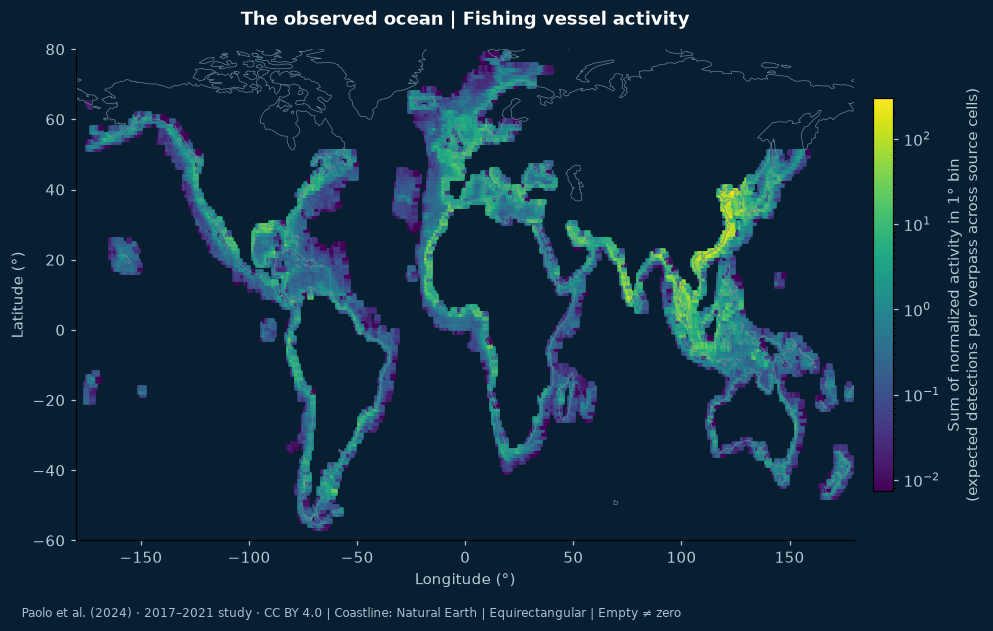

In [3]:
REGION = (-180, -60, 180, 80)  # west, south, east, north in degrees
fig = lab.map2d("tot_fishing", bbox=REGION)
plt.show()

In [4]:
lab.show(lab.interactive_map())

<iframe title="Zoom into the evidence | observed SAR activity, 2017–2021" srcdoc="<html>
<head><meta charset="utf-8" /></head>
<body>
 <div> <script type="text/javascript">window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script charset="utf-8" src="https://cdn.plot.ly/plotly-3.3.0.min.js" integrity="sha256-bO3dS6yCpk9aK4gUpNELtCiDeSYvGYnK7jFI58NQnHI=" crossorigin="anonymous"></script> <div id="eedd3e73-6109-4a70-a2a0-74076dc0d6ae" class="plotly-graph-div" style="height:580px; width:100%;"></div> <script type="text/javascript"> window.PLOTLYENV=window.PLOTLYENV || {}; if (document.getElementById("eedd3e73-6109-4a70-a2a0-74076dc0d6ae")) { Plotly.newPlot( "eedd3e73-6109-4a70-a2a0-74076dc0d6ae", [{"hoverinfo":"skip","line":{"color":"#8ba5b5","width":0.6},"mode":"lines","showlegend":false,"x":{"dtype":"f8","bdata":"YK5FC9B2ZMBLXMe4YmNkwGLaN\u002ffXJ2TAb4CZ7+AHZMCpTZzcb+9jwJ3xfXGp5mPA+z2xThUkZMDMBwQ6E05kwMP0vYbgYGTADTm2niFiZMBgrkUL0HZkwA=="},"y":{"dtype":"f8","bdata":"nRN7aB+mU8D3OqkvS45TwEBs6dFUmFPAFEAxsmSsU8D5o6gz98JTwGx2pPrO31PADHVY4ZboU8D+fcaFA9JTwALYgAhxu1PAcqjfha23U8CdE3toH6ZTwA=="},"type":"scattergl"},{"hoverinfo":"skip","line":{"color":"#8ba5b5","width":0.6},"mode":"lines","showlegend":false,"x":{"dtype":"f8","bdata":"0XmNXaLKGMDECOHRxiEYwPjhICHKJxvAWcFvQ4wfIcBIwr6dRPQjwPTCnQsjVSLA8fRKWYZgI8C8Bn3p7acgwFpFf2jmSR7AIxKFlnXvGsDIemr11aUWwNF5jV2iyhjA"},"y":{"dtype":"f8","bdata":"vhOzXgzvSkCBCdy6m5NKQOuM74tLIUpADRe5p6vVSUB7a2CrBOlJQCsWvymsbkpAxXO2gNDwSkAKSWb1DlVLQJG3XP3YkEtArmTHRiCWS0C6oSk7\u002fUZLQL4Ts14M70pA"},"type":"scattergl"},{"hoverinfo":"skip","line":{"color":"#8ba5b5","width":0.6},"mode":"lines","showlegend":false,"x":{"dtype":"f8","bdata":"O+RmuAGgYUBtb7ckh9dhQP9Z8+OvEmJA53Pudr0oYkC4lV6bjTpiQCKnr+drP2JAdo2WA710YkCHpuz0g3xiQLvQXKcRX2JAfV7x1CNmYkAOgo5WtYJiQJDaxMl9l2JAlUiil9GpYkAxI7w9iKhiQBCugEI9wWJANQu0O6S3YkDaccPvptliQO0NvjAZ1mJA7s1vmOjAYkCuKvuuCLliQDz2s1iKnWJAGVWGcTd9YkAc746MVWRiQKJgxhQsUmJAR68GKI1BYkBa12g50BdiQEq05PG0\u002fGFAf0sA\u002finpYUB1zHnGPu1hQF0ZVBsc1GFADJV\u002fLS\u002fCYUDvHMpQFaFhQDDYDduWhGFAQtDRqhZkYUCj5UAPNVxhQMHHYMWpM2FAzcmLTEBBYUBnDd5XZVVhQJQyqaENTWFAdv2C3bA9YUAtsp3vp\u002f9gQJZfBmNE5WBAhSUeUDa1YEBsskY9xKtgQH8WS5F8n2BADQBV3DiYYEC14hsKH5hgQGYucHmsf2BA1hwgmCOiYEC4W5ID9rhgQKZiY15HtmBAJm+AmW+HYEBDxqNUwnpgQIqryr4rXmBAAUwZOKBQYEAxQQ3fwntgQPaVB+kpjGBAbJT1m4m\u002fYEBg6Xx4lsRgQAPtDimGzWBApvELr6TuYECwrgrUYglhQFgDlIYaLmFAdjOjH41KYUD\u002f6nHf6mVhQD83NGWnfWFAO+RmuAGgYUA="},"y":{"dtype":"f8","bdata":"J0ut9xvNBMCDUrRyL1AKwF980R4v5A7A\u002fRadLLV+EcCiCRSxiIETwJ\u002fkDpvI3BXAcxB0tKpVGMCGAyFZwHQawMi3dw364hrAnkDYKVaNHcDj++JSlRYgwBgjEoWWNSLAnYNnQpMkIsB7uyU5YAcjwNUgzO1eXiPAzO80mfG+I8BNhXgkXpYkwHnou1tZKiXAjNmSVRFOJcArMc9KWskkwG9jsyPVjyTAdR2qKclCJMANObaeIfwiwNFcp5GW4iHAyJV6FoQiIMDxLEFGQIUewNMwfERMqR\u002fAt+wQ\u002f7B9IMBAbOnRVPchwMNKBRVVpyLAFCUhkbZRIsDL2qZ4XDwiwODVcmcmmCDA+wRQjCwxIMCzzY3pCcMgwGqjOh3I0iDA4nfTLTtkHsBHcvkP6UcdwA6g3\u002fdv7hjA8G5lic6SFcDTTPc6qS8SwOM3hZUK2hHA2c9iKZJPDMAXR+UmahkQwAWKWMSwcxDAdHy0OGP4DcAqi8Iuin4KwMyZ7Qp9kAbA9+rjoe+uA8B3aFiMutYDwIzyzMthtwHAx2Xc1ECzAcDeV+VC5d\u002f5v+bOTDCc6\u002fa\u002fi8OZX80B7r8xl1RtN0Hmv5lFKLaCpte\u002fnWNA9nr36L9Td2UXDG7yvw+XHHdKJwbA56bNOA3xCsDK\u002fKNv0nQCwDz59NiWQfu\u002fPGagMv49+78uU5PgDWkAwBKDwMqhRQPAJ0ut9xvNBMA="},"type":"scattergl"},{"hoverinfo":"skip","line":{"color":"#8ba5b5","width":0.6},"mode":"lines","showlegend":false,"x":{"dtype":"f8","bdata":"\u002frRRnQ6NXEAHeNLCZaZcQLt+wW7Y3FxAuvjbniAOXUDRzmkWaC5dQIat2cpLSF1AbF7VWS1pXUBwXwfOGWxdQESHwJFAll1AvsCsUKTLXUBCd0mcFcddQMQKt3wknF1AhVs+kpKnXUBau+1Cc3hdQOIDO\u002f4LVF1Am1q21heDXUCnH9RFCnhdQLbY7bPKv11Avr9Be\u002fVzXUCwWS4bnV5dQOUJhJ1iYV1ALAyR09cjXUD9bOS6KSJdQOVDUDV6CV1AKHy2Dg4AXUDknq7uWLdcQB9N9WT+nVxAMKAX7lxwXEArUfaWclBcQHiAJy1cBFxAjSRBuALtW0D7ljldFsNbQMlVLH5TjltA+wYmN4qEW0DPwMjLmmRbQJNWfEPhRVtAdZFCWfg8W0B7vma5bERbQK0vEtpyaltAQ3OdRlqZW0A3NdB8zspbQL73N2iv11tAEVFM3gDzW0ANGvonuD9cQB9LH7qgbVxA\u002frRRnQ6NXEA="},"y":{"dtype":"f8","bdata":"TkS\u002ftn4aEkA5Kcx7nJkTQJjArbt5yhVAflNYqaCSGEAoKEUr97IbQJrRj4ZTthtAu+6tSEywGU

## The denominator changes the story
Compute the unmatched modeled fishing share yourself. Do not use the continent table's precomputed `perc_dark_*` or `dark_fishing_frac` columns. A minimum-activity screen prevents tiny denominators from dominating this descriptive comparison; it does not establish statistical significance.

,lon,lat,tot_fishing,dark_fishing,unmatched_share,overpasses_2017_2021
29831,5.3,53.3,3.607993,0.192535,0.053364,890.509386
55801,5.1,53.1,3.281749,0.418205,0.127434,1169.056271
55672,5.1,53.3,3.080580,0.180956,0.058741,1170.880446
17445,8.5,54.1,2.755510,1.479017,0.536749,1016.859537
4418,6.1,53.5,2.457120,0.157423,0.064068,1170.238842
23610,8.5,54.3,2.246898,1.532652,0.682119,1134.615076
10628,-0.7,49.5,2.161006,0.778840,0.360406,891.689605
17068,4.7,52.9,2.156063,0.136846,0.063470,1181.125837
21307,2.9,51.3,2.130363,0.262959,0.123434,1179.271036
21317,3.3,51.5,2.043301,0.248521,0.121627,1177.843766


Cells retained: 122 of 8532 in the teaching window


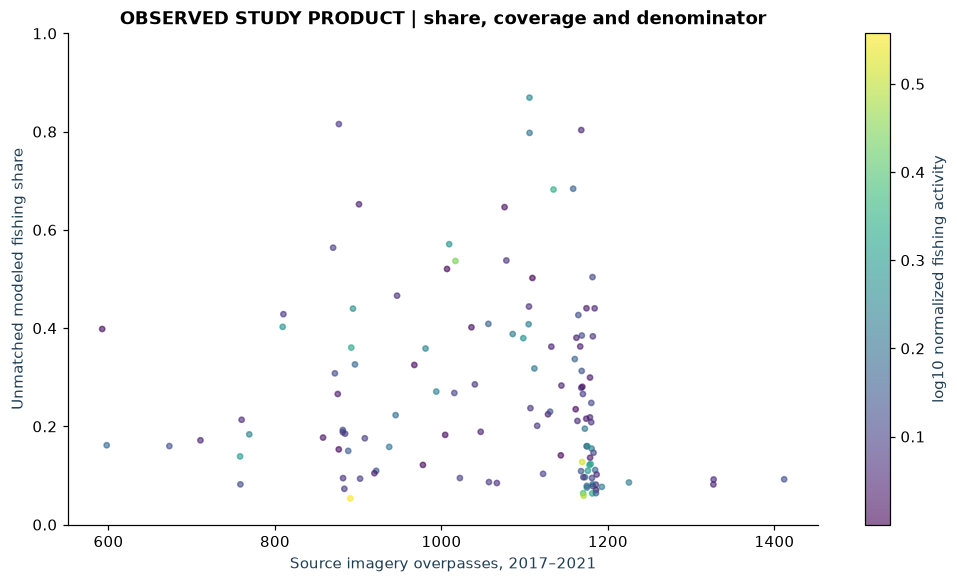

In [5]:
MIN_ACTIVITY = 1.0
region = observed[observed.lon.between(-12,32) & observed.lat.between(48,66)].copy()
region["unmatched_share"] = region.dark_fishing / region.tot_fishing.where(region.tot_fishing > 0)
enough = region[region.tot_fishing >= MIN_ACTIVITY]
display(enough[["lon", "lat", "tot_fishing", "dark_fishing", "unmatched_share", "overpasses_2017_2021"]].sort_values("tot_fishing", ascending=False).head(12))
print("Cells retained:", len(enough), "of", len(region), "in the teaching window")
fig, ax = plt.subplots()
p = ax.scatter(enough.overpasses_2017_2021, enough.unmatched_share,
               c=np.log10(enough.tot_fishing), cmap="viridis", s=12, alpha=.6)
ax.set(xlabel="Source imagery overpasses, 2017–2021", ylabel="Unmatched modeled fishing share", ylim=(0,1),
       title="OBSERVED STUDY PRODUCT | share, coverage and denominator")
fig.colorbar(p, ax=ax, label="log10 normalized fishing activity")
plt.show()

## Compare components across study regions
The continent figures use the deposit's aggregate estimates. They do not enumerate unique vessels, indicate violations, or describe all fleets. Compare the matched and unmatched **components**, not the source's ambiguously named fraction fields.

,continent,AIS fishing,dark fishing
0,Africa,394.83,1480.90
1,Asia,4264.58,15792.46
2,Australia,114.77,363.51
3,Europe,1654.22,1137.48
4,North America,343.09,1669.25
5,South America,232.82,796.07


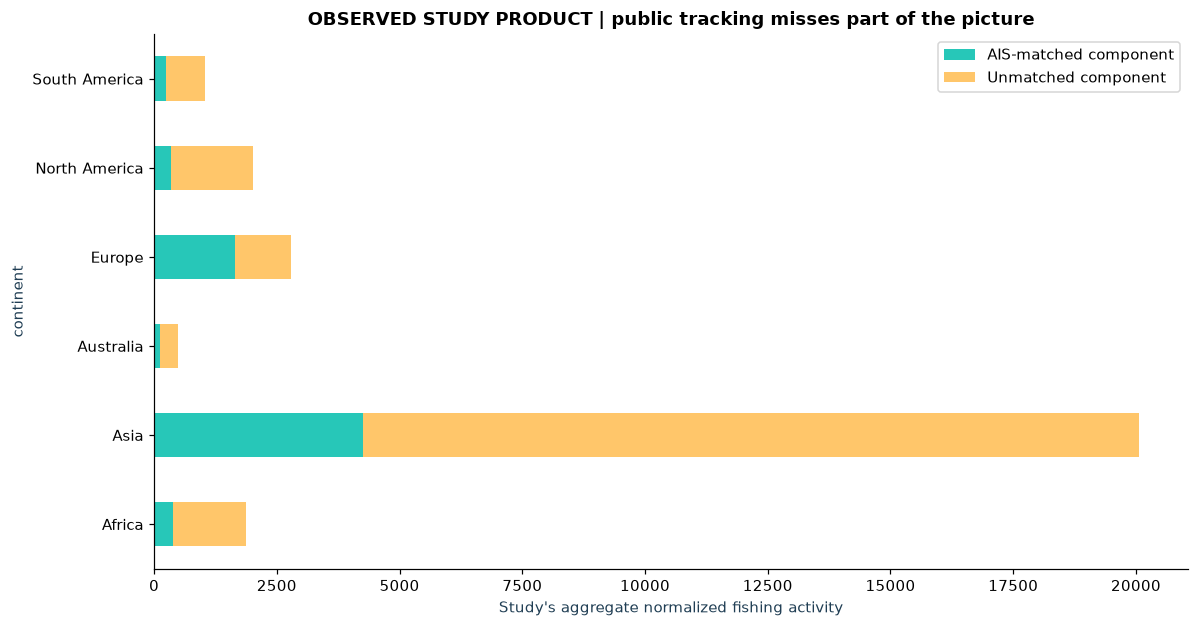

In [6]:
continents = pd.read_csv(lab.DATA / "vessels_bycontinent_v20230803.csv")
cols = ["continent", "AIS fishing", "dark fishing"]
display(continents[cols].round(2))
ax = continents.set_index("continent")[["AIS fishing", "dark fishing"]].plot.barh(stacked=True, color=[lab.TEAL, lab.AMBER])
ax.set(xlabel="Study's aggregate normalized fishing activity", title="OBSERVED STUDY PRODUCT | public tracking misses part of the picture")
ax.legend(["AIS-matched component", "Unmatched component"])
plt.tight_layout(); plt.show()

## Interpret before exporting
1. Which claims depend on the sampling design?
2. How would equal-area bins change a density comparison?
3. Would an unmatched fraction identify intentional concealment?
4. What additional data would connect this activity to a fish stock?

**Takeaway:** observations make activity visible; denominators and coverage determine which comparisons are defensible.